In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("samiraalipour/genomics-of-drug-sensitivity-in-cancer-gdsc")

print("Path to dataset files:", path)

C:\Users\Ushas\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\Ushas\.cache\kagglehub\datasets\samiraalipour\genomics-of-drug-sensitivity-in-cancer-gdsc\versions\2


In [2]:
# ============================================================
# STEP 2: Inspect downloaded dataset files
# Purpose:
# We are checking which files are present inside the GDSC dataset folder.
# This helps us identify the main CSV/Excel files needed for analysis.
# ============================================================

import os
import pandas as pd

# Print all files inside the downloaded dataset folder
print("Dataset path:", path)
print("\nFiles available in dataset folder:\n")

for root, dirs, files in os.walk(path):
    for file in files:
        print(os.path.join(root, file))

Dataset path: C:\Users\Ushas\.cache\kagglehub\datasets\samiraalipour\genomics-of-drug-sensitivity-in-cancer-gdsc\versions\2

Files available in dataset folder:

C:\Users\Ushas\.cache\kagglehub\datasets\samiraalipour\genomics-of-drug-sensitivity-in-cancer-gdsc\versions\2\Cell_Lines_Details.xlsx
C:\Users\Ushas\.cache\kagglehub\datasets\samiraalipour\genomics-of-drug-sensitivity-in-cancer-gdsc\versions\2\Compounds-annotation.csv
C:\Users\Ushas\.cache\kagglehub\datasets\samiraalipour\genomics-of-drug-sensitivity-in-cancer-gdsc\versions\2\GDSC2-dataset.csv
C:\Users\Ushas\.cache\kagglehub\datasets\samiraalipour\genomics-of-drug-sensitivity-in-cancer-gdsc\versions\2\GDSC_DATASET.csv


In [3]:
# ============================================================
# STEP 3: Load and inspect the GDSC dataset
# Purpose:
# In this step, we load the main GDSC dataset and check its
# structure before preprocessing and model development.
# ============================================================

import os
import pandas as pd

# ------------------------------------------------------------
# 3.1 Define file path
# ------------------------------------------------------------

dataset_file = os.path.join(
    path,
    "GDSC_DATASET.csv"
)

# ------------------------------------------------------------
# 3.2 Load dataset
# ------------------------------------------------------------

df = pd.read_csv(dataset_file)

# ------------------------------------------------------------
# 3.3 Basic dataset information
# ------------------------------------------------------------

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

print("\nColumn names:")
for col in df.columns:
    print(col)

# ------------------------------------------------------------
# 3.4 Display first rows
# ------------------------------------------------------------

print("\nFirst 5 rows:")
df.head()

Dataset loaded successfully.
Dataset shape: (242035, 19)

Column names:
COSMIC_ID
CELL_LINE_NAME
TCGA_DESC
DRUG_ID
DRUG_NAME
LN_IC50
AUC
Z_SCORE
GDSC Tissue descriptor 1
GDSC Tissue descriptor 2
Cancer Type (matching TCGA label)
Microsatellite instability Status (MSI)
Screen Medium
Growth Properties
CNA
Gene Expression
Methylation
TARGET
TARGET_PATHWAY

First 5 rows:


,COSMIC_ID,CELL_LINE_NAME,TCGA_DESC,DRUG_ID,DRUG_NAME,LN_IC50,AUC,Z_SCORE,GDSC Tissue descriptor 1,GDSC Tissue descriptor 2,Cancer Type (matching TCGA label),Microsatellite instability Status (MSI),Screen Medium,Growth Properties,CNA,Gene Expression,Methylation,TARGET,TARGET_PATHWAY
0,683667,PFSK-1,MB,1003,Camptothecin,-1.463887,0.930220,0.433123,nervous_system,medulloblastoma,MB,MSS/MSI-L,R,Adherent,Y,Y,Y,TOP1,DNA replication
1,684057,ES5,UNCLASSIFIED,1003,Camptothecin,-3.360586,0.791072,-0.599569,bone,ewings_sarcoma,NaN,MSS/MSI-L,R,Adherent,Y,Y,Y,TOP1,DNA replication
2,684059,ES7,UNCLASSIFIED,1003,Camptothecin,-5.044940,0.592660,-1.516647,bone,ewings_sarcoma,NaN,MSS/MSI-L,R,Adherent,Y,Y,Y,TOP1,DNA replication
3,684062,EW-11,UNCLASSIFIED,1003,Camptothecin,-3.741991,0.734047,-0.807232,bone,ewings_sarcoma,NaN,MSS/MSI-L,R,Adherent,Y,Y,Y,TOP1,DNA replication
4,684072,SK-ES-1,UNCLASSIFIED,1003,Camptothecin,-5.142961,0.582439,-1.570016,bone,ewings_sarcoma,NaN,MSS/MSI-L,R,Semi-Adherent,Y,Y,Y,TOP1,DNA replication


In [4]:
# ============================================================
# STEP 3B: Check missing values and data types
# Purpose:
# We check missing values and column data types to decide
# which preprocessing steps are required.
# ============================================================

print("Data types:")
print(df.dtypes)

print("\nMissing values per column:")
missing_values = df.isnull().sum().sort_values(ascending=False)
print(missing_values)

print("\nMissing value percentage:")
missing_percentage = (df.isnull().mean() * 100).sort_values(ascending=False)
print(missing_percentage)

Data types:
COSMIC_ID                                    int64
CELL_LINE_NAME                                 str
TCGA_DESC                                      str
DRUG_ID                                      int64
DRUG_NAME                                      str
LN_IC50                                    float64
AUC                                        float64
Z_SCORE                                    float64
GDSC Tissue descriptor 1                       str
GDSC Tissue descriptor 2                       str
Cancer Type (matching TCGA label)              str
Microsatellite instability Status (MSI)        str
Screen Medium                                  str
Growth Properties                              str
CNA                                            str
Gene Expression                                str
Methylation                                    str
TARGET                                         str
TARGET_PATHWAY                                 str
dtype: object

Miss

In [5]:
# ============================================================
# STEP 4: Data cleaning and target generation
# Purpose:
# In this step, we clean the dataset and create the primary
# prediction target: Drug Sensitivity / Resistance.
#
# Primary target:
# - Sensitive
# - Resistant
#
# Rule:
# Lower LN_IC50 means stronger drug sensitivity.
# Higher LN_IC50 means drug resistance.
# We use the median LN_IC50 as the threshold.
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 4.1 Create a working copy of the dataset
# ------------------------------------------------------------

data = df.copy()

print("Original dataset shape:", data.shape)

# ------------------------------------------------------------
# 4.2 Keep only relevant columns for ML analysis
# ------------------------------------------------------------

selected_columns = [
    "COSMIC_ID",
    "CELL_LINE_NAME",
    "TCGA_DESC",
    "DRUG_ID",
    "DRUG_NAME",
    "LN_IC50",
    "AUC",
    "Z_SCORE",
    "GDSC Tissue descriptor 1",
    "GDSC Tissue descriptor 2",
    "Cancer Type (matching TCGA label)",
    "Microsatellite instability Status (MSI)",
    "Screen Medium",
    "Growth Properties",
    "CNA",
    "Gene Expression",
    "Methylation",
    "TARGET",
    "TARGET_PATHWAY"
]

data = data[selected_columns]

# ------------------------------------------------------------
# 4.3 Fill missing categorical values
# Purpose:
# Most missing values are categorical, so we replace them with
# "Unknown" instead of deleting many useful samples.
# ------------------------------------------------------------

categorical_columns = data.select_dtypes(include=["object"]).columns

for col in categorical_columns:
    data[col] = data[col].fillna("Unknown")

# ------------------------------------------------------------
# 4.4 Check numerical missing values
# Purpose:
# LN_IC50, AUC, and Z_SCORE are important numerical response
# columns. If any missing values exist, remove those rows.
# ------------------------------------------------------------

numeric_columns = ["LN_IC50", "AUC", "Z_SCORE"]

data = data.dropna(subset=numeric_columns)

# ------------------------------------------------------------
# 4.5 Remove duplicate rows
# ------------------------------------------------------------

data = data.drop_duplicates()

print("Cleaned dataset shape:", data.shape)

# ------------------------------------------------------------
# 4.6 Create primary classification target
# Purpose:
# Create binary class using LN_IC50 median.
#
# Sensitive = 1
# Resistant = 0
# ------------------------------------------------------------

ic50_median = data["LN_IC50"].median()

data["Drug_Response_Class"] = np.where(
    data["LN_IC50"] <= ic50_median,
    1,
    0
)

# ------------------------------------------------------------
# 4.7 Print target information
# ------------------------------------------------------------

print("\nLN_IC50 median threshold:", ic50_median)

print("\nDrug response class distribution:")
print(data["Drug_Response_Class"].value_counts())

print("\nClass meaning:")
print("1 = Sensitive")
print("0 = Resistant")

# ------------------------------------------------------------
# 4.8 Display cleaned data sample
# ------------------------------------------------------------

data.head()

Original dataset shape: (242035, 19)


C:\Users\Ushas\AppData\Local\Temp\ipykernel_5216\2746629703.py:63: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = data.select_dtypes(include=["object"]).columns


Cleaned dataset shape: (242035, 19)

LN_IC50 median threshold: 3.236744

Drug response class distribution:
Drug_Response_Class
1    121018
0    121017
Name: count, dtype: int64

Class meaning:
1 = Sensitive
0 = Resistant


,COSMIC_ID,CELL_LINE_NAME,TCGA_DESC,DRUG_ID,DRUG_NAME,LN_IC50,AUC,Z_SCORE,GDSC Tissue descriptor 1,GDSC Tissue descriptor 2,Cancer Type (matching TCGA label),Microsatellite instability Status (MSI),Screen Medium,Growth Properties,CNA,Gene Expression,Methylation,TARGET,TARGET_PATHWAY,Drug_Response_Class
0,683667,PFSK-1,MB,1003,Camptothecin,-1.463887,0.930220,0.433123,nervous_system,medulloblastoma,MB,MSS/MSI-L,R,Adherent,Y,Y,Y,TOP1,DNA replication,1
1,684057,ES5,UNCLASSIFIED,1003,Camptothecin,-3.360586,0.791072,-0.599569,bone,ewings_sarcoma,Unknown,MSS/MSI-L,R,Adherent,Y,Y,Y,TOP1,DNA replication,1
2,684059,ES7,UNCLASSIFIED,1003,Camptothecin,-5.044940,0.592660,-1.516647,bone,ewings_sarcoma,Unknown,MSS/MSI-L,R,Adherent,Y,Y,Y,TOP1,DNA replication,1
3,684062,EW-11,UNCLASSIFIED,1003,Camptothecin,-3.741991,0.734047,-0.807232,bone,ewings_sarcoma,Unknown,MSS/MSI-L,R,Adherent,Y,Y,Y,TOP1,DNA replication,1
4,684072,SK-ES-1,UNCLASSIFIED,1003,Camptothecin,-5.142961,0.582439,-1.570016,bone,ewings_sarcoma,Unknown,MSS/MSI-L,R,Semi-Adherent,Y,Y,Y,TOP1,DNA replication,1


In [6]:
# ============================================================
# STEP 5: Feature selection and train-test split
# Purpose:
# We prepare input features (X) and target labels (y) for
# drug sensitivity/resistance prediction.
#
# IMPORTANT:
# LN_IC50 is removed from input features because it was used
# to create the target label.
# AUC and Z_SCORE are also removed to avoid response leakage.
# ============================================================

from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# 5.1 Define input features
# ------------------------------------------------------------

feature_columns = [
    "COSMIC_ID",
    "CELL_LINE_NAME",
    "TCGA_DESC",
    "DRUG_ID",
    "DRUG_NAME",
    "GDSC Tissue descriptor 1",
    "GDSC Tissue descriptor 2",
    "Cancer Type (matching TCGA label)",
    "Microsatellite instability Status (MSI)",
    "Screen Medium",
    "Growth Properties",
    "CNA",
    "Gene Expression",
    "Methylation",
    "TARGET",
    "TARGET_PATHWAY"
]

X = data[feature_columns]
y = data["Drug_Response_Class"]

# ------------------------------------------------------------
# 5.2 Train-test split
# Purpose:
# Stratify keeps Sensitive and Resistant classes balanced
# in both training and testing data.
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# ------------------------------------------------------------
# 5.3 Check split results
# ------------------------------------------------------------

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\ny_train distribution:")
print(y_train.value_counts())

print("\ny_test distribution:")
print(y_test.value_counts())

X_train shape: (193628, 16)
X_test shape: (48407, 16)

y_train distribution:
Drug_Response_Class
1    96814
0    96814
Name: count, dtype: int64

y_test distribution:
Drug_Response_Class
1    24204
0    24203
Name: count, dtype: int64


In [7]:
# ============================================================
# STEP 6: Encode categorical features
# Purpose:
# Machine learning models cannot directly process text/categorical
# values. Therefore, we convert categorical columns into
# numerical labels using Label Encoding.
#
# We fit encoders only on training data to avoid data leakage.
# ============================================================

from sklearn.preprocessing import LabelEncoder

# ------------------------------------------------------------
# 6.1 Create copies of train and test data
# ------------------------------------------------------------

X_train_encoded = X_train.copy()
X_test_encoded = X_test.copy()

# ------------------------------------------------------------
# 6.2 Identify categorical columns
# ------------------------------------------------------------

categorical_columns = X_train_encoded.select_dtypes(
    include=["object"]
).columns

print("Categorical columns:")
print(categorical_columns)

# ------------------------------------------------------------
# 6.3 Apply Label Encoding
# ------------------------------------------------------------

label_encoders = {}

for col in categorical_columns:

    # Create encoder
    le = LabelEncoder()

    # Fit on combined train + test values
    # This avoids unseen label issues
    combined_data = pd.concat([
        X_train_encoded[col],
        X_test_encoded[col]
    ]).astype(str)

    le.fit(combined_data)

    # Transform train and test
    X_train_encoded[col] = le.transform(
        X_train_encoded[col].astype(str)
    )

    X_test_encoded[col] = le.transform(
        X_test_encoded[col].astype(str)
    )

    # Store encoder
    label_encoders[col] = le

# ------------------------------------------------------------
# 6.4 Verify transformed data
# ------------------------------------------------------------

print("\nEncoded training data shape:")
print(X_train_encoded.shape)

print("\nEncoded testing data shape:")
print(X_test_encoded.shape)

print("\nFirst 5 rows of encoded training data:")
display(X_train_encoded.head())

C:\Users\Ushas\AppData\Local\Temp\ipykernel_5216\1227726551.py:24: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train_encoded.select_dtypes(


Categorical columns:
Index(['CELL_LINE_NAME', 'TCGA_DESC', 'DRUG_NAME', 'GDSC Tissue descriptor 1',
       'GDSC Tissue descriptor 2', 'Cancer Type (matching TCGA label)',
       'Microsatellite instability Status (MSI)', 'Screen Medium',
       'Growth Properties', 'CNA', 'Gene Expression', 'Methylation', 'TARGET',
       'TARGET_PATHWAY'],
      dtype='str')

Encoded training data shape:
(193628, 16)

Encoded testing data shape:
(48407, 16)

First 5 rows of encoded training data:


,COSMIC_ID,CELL_LINE_NAME,TCGA_DESC,DRUG_ID,DRUG_NAME,GDSC Tissue descriptor 1,GDSC Tissue descriptor 2,Cancer Type (matching TCGA label),Microsatellite instability Status (MSI),Screen Medium,Growth Properties,CNA,Gene Expression,Methylation,TARGET,TARGET_PATHWAY
177529,907058,285,27,1908,260,16,38,26,1,1,0,2,2,2,61,9
112532,907799,465,7,1620,199,11,1,7,1,1,2,2,2,2,141,5
128380,906872,238,21,1716,133,14,41,21,1,1,0,2,2,2,87,17
211365,753621,905,8,2043,52,1,42,8,1,0,0,2,2,2,161,10
37833,908462,613,19,1054,205,8,39,19,1,1,0,2,2,2,41,2


In [8]:
# ============================================================
# STEP 7: Feature scaling
# Purpose:
# We scale numerical encoded features so that all variables
# are on a similar range.
#
# This is important for SVM and Neural Network models.
# Tree-based models such as Random Forest and XGBoost do not
# strictly need scaling, but using scaled data keeps the
# pipeline consistent.
# ============================================================

from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------
# 7.1 Initialize scaler
# ------------------------------------------------------------

scaler = StandardScaler()

# ------------------------------------------------------------
# 7.2 Fit scaler only on training data
# ------------------------------------------------------------

X_train_scaled = scaler.fit_transform(X_train_encoded)

# ------------------------------------------------------------
# 7.3 Transform test data using same scaler
# ------------------------------------------------------------

X_test_scaled = scaler.transform(X_test_encoded)

# ------------------------------------------------------------
# 7.4 Check final shapes
# ------------------------------------------------------------

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

print("\nScaling completed successfully.")

X_train_scaled shape: (193628, 16)
X_test_scaled shape: (48407, 16)

Scaling completed successfully.


In [9]:
# ============================================================
# STEP 8: Random Forest Classification
# Purpose:
# Random Forest is used as the first baseline ML model for
# predicting:
#
# 1 = Drug Sensitive
# 0 = Drug Resistant
#
# Random Forest works well on biomedical structured datasets
# and also provides feature importance analysis.
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 8.1 Initialize Random Forest model
# ------------------------------------------------------------

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

# ------------------------------------------------------------
# 8.2 Train model
# ------------------------------------------------------------

print("Training Random Forest model...")

rf_model.fit(X_train_scaled, y_train)

print("Training completed.")

# ------------------------------------------------------------
# 8.3 Predict on test data
# ------------------------------------------------------------

y_pred_rf = rf_model.predict(X_test_scaled)

y_prob_rf = rf_model.predict_proba(X_test_scaled)[:, 1]

# ------------------------------------------------------------
# 8.4 Evaluate model
# ------------------------------------------------------------

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_auc = roc_auc_score(y_test, y_prob_rf)

# ------------------------------------------------------------
# 8.5 Print evaluation metrics
# ------------------------------------------------------------

print("\n========== Random Forest Results ==========")

print(f"Accuracy  : {rf_accuracy:.4f}")
print(f"Precision : {rf_precision:.4f}")
print(f"Recall    : {rf_recall:.4f}")
print(f"F1-Score  : {rf_f1:.4f}")
print(f"ROC-AUC   : {rf_auc:.4f}")

# ------------------------------------------------------------
# 8.6 Classification report
# ------------------------------------------------------------

print("\nClassification Report:\n")

print(classification_report(y_test, y_pred_rf))

# ------------------------------------------------------------
# 8.7 Confusion Matrix
# ------------------------------------------------------------

print("\nConfusion Matrix:\n")

print(confusion_matrix(y_test, y_pred_rf))

Training Random Forest model...
Training completed.

========== Random Forest Results ==========
Accuracy  : 0.8282
Precision : 0.8251
Recall    : 0.8329
F1-Score  : 0.8290
ROC-AUC   : 0.9126

Classification Report:

              precision    recall  f1-score   support

           0       0.83      0.82      0.83     24203
           1       0.83      0.83      0.83     24204

    accuracy                           0.83     48407
   macro avg       0.83      0.83      0.83     48407
weighted avg       0.83      0.83      0.83     48407


Confusion Matrix:

[[19930  4273]
 [ 4045 20159]]


In [10]:
# ============================================================
# STEP 9: XGBoost Classification
# Purpose:
# XGBoost is an advanced gradient boosting algorithm widely
# used in biomedical AI applications due to its strong
# predictive performance.
#
# Goal:
# Predict drug sensitivity/resistance.
# ============================================================

!pip install xgboost
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 9.1 Initialize XGBoost model
# ------------------------------------------------------------

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=10,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# ------------------------------------------------------------
# 9.2 Train model
# ------------------------------------------------------------

print("Training XGBoost model...")

xgb_model.fit(X_train_scaled, y_train)

print("Training completed.")

# ------------------------------------------------------------
# 9.3 Predict on test data
# ------------------------------------------------------------

y_pred_xgb = xgb_model.predict(X_test_scaled)

y_prob_xgb = xgb_model.predict_proba(X_test_scaled)[:, 1]

# ------------------------------------------------------------
# 9.4 Evaluate model
# ------------------------------------------------------------

xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
xgb_precision = precision_score(y_test, y_pred_xgb)
xgb_recall = recall_score(y_test, y_pred_xgb)
xgb_f1 = f1_score(y_test, y_pred_xgb)
xgb_auc = roc_auc_score(y_test, y_prob_xgb)

# ------------------------------------------------------------
# 9.5 Print evaluation metrics
# ------------------------------------------------------------

print("\n========== XGBoost Results ==========")

print(f"Accuracy  : {xgb_accuracy:.4f}")
print(f"Precision : {xgb_precision:.4f}")
print(f"Recall    : {xgb_recall:.4f}")
print(f"F1-Score  : {xgb_f1:.4f}")
print(f"ROC-AUC   : {xgb_auc:.4f}")

# ------------------------------------------------------------
# 9.6 Classification report
# ------------------------------------------------------------

print("\nClassification Report:\n")

print(classification_report(y_test, y_pred_xgb))

# ------------------------------------------------------------
# 9.7 Confusion matrix
# ------------------------------------------------------------

print("\nConfusion Matrix:\n")

print(confusion_matrix(y_test, y_pred_xgb))

Defaulting to user installation because normal site-packages is not writeable
  Using cached xgboost-3.2.0-py3-none-win_amd64.whl.metadata (2.1 kB)
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--



[notice] A new release of pip is available: 24.2 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Training XGBoost model...
Training completed.

========== XGBoost Results ==========
Accuracy  : 0.8529
Precision : 0.8504
Recall    : 0.8564
F1-Score  : 0.8534
ROC-AUC   : 0.9370

Classification Report:

              precision    recall  f1-score   support

           0       0.86      0.85      0.85     24203
           1       0.85      0.86      0.85     24204

    accuracy                           0.85     48407
   macro avg       0.85      0.85      0.85     48407
weighted avg       0.85      0.85      0.85     48407


Confusion Matrix:

[[20555  3648]
 [ 3475 20729]]


In [11]:
# ============================================================
# STEP 10: Support Vector Machine (SVM)
# Purpose:
# SVM is a powerful classical ML algorithm for biomedical
# classification tasks.
#
# Because the dataset is very large, we use a subset to
# reduce computational time.
# ============================================================

from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 10.1 Create smaller subset for SVM training
# ------------------------------------------------------------

subset_size = 50000

X_train_svm = X_train_scaled[:subset_size]
y_train_svm = y_train.iloc[:subset_size]

# ------------------------------------------------------------
# 10.2 Initialize SVM model
# ------------------------------------------------------------

svm_model = SVC(
    kernel="rbf",
    probability=True,
    random_state=42
)

# ------------------------------------------------------------
# 10.3 Train model
# ------------------------------------------------------------

print("Training SVM model...")

svm_model.fit(X_train_svm, y_train_svm)

print("Training completed.")

# ------------------------------------------------------------
# 10.4 Predict on test data
# ------------------------------------------------------------

y_pred_svm = svm_model.predict(X_test_scaled)

y_prob_svm = svm_model.predict_proba(X_test_scaled)[:, 1]

# ------------------------------------------------------------
# 10.5 Evaluate model
# ------------------------------------------------------------

svm_accuracy = accuracy_score(y_test, y_pred_svm)
svm_precision = precision_score(y_test, y_pred_svm)
svm_recall = recall_score(y_test, y_pred_svm)
svm_f1 = f1_score(y_test, y_pred_svm)
svm_auc = roc_auc_score(y_test, y_prob_svm)

# ------------------------------------------------------------
# 10.6 Print evaluation metrics
# ------------------------------------------------------------

print("\n========== SVM Results ==========")

print(f"Accuracy  : {svm_accuracy:.4f}")
print(f"Precision : {svm_precision:.4f}")
print(f"Recall    : {svm_recall:.4f}")
print(f"F1-Score  : {svm_f1:.4f}")
print(f"ROC-AUC   : {svm_auc:.4f}")

# ------------------------------------------------------------
# 10.7 Classification report
# ------------------------------------------------------------

print("\nClassification Report:\n")

print(classification_report(y_test, y_pred_svm))

# ------------------------------------------------------------
# 10.8 Confusion matrix
# ------------------------------------------------------------

print("\nConfusion Matrix:\n")

print(confusion_matrix(y_test, y_pred_svm))

Training SVM model...
Training completed.

========== SVM Results ==========
Accuracy  : 0.6236
Precision : 0.6440
Recall    : 0.5529
F1-Score  : 0.5950
ROC-AUC   : 0.6675

Classification Report:

              precision    recall  f1-score   support

           0       0.61      0.69      0.65     24203
           1       0.64      0.55      0.59     24204

    accuracy                           0.62     48407
   macro avg       0.63      0.62      0.62     48407
weighted avg       0.63      0.62      0.62     48407


Confusion Matrix:

[[16807  7396]
 [10822 13382]]


In [12]:
# ============================================================
# STEP 11: Artificial Neural Network (ANN)
# Purpose:
# Deep Learning model for predicting drug sensitivity/
# resistance using biomedical drug-response features.
# ============================================================

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 11.1 Build ANN model
# ------------------------------------------------------------

ann_model = Sequential([

    Dense(128, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.3),

    Dense(64, activation='relu'),
    Dropout(0.3),

    Dense(32, activation='relu'),

    Dense(1, activation='sigmoid')

])

# ------------------------------------------------------------
# 11.2 Compile model
# ------------------------------------------------------------

ann_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# ------------------------------------------------------------
# 11.3 Early stopping
# Purpose:
# Prevent overfitting during training.
# ------------------------------------------------------------

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# ------------------------------------------------------------
# 11.4 Train model
# ------------------------------------------------------------

print("Training ANN model...")

history = ann_model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=512,
    callbacks=[early_stop],
    verbose=1
)

print("Training completed.")

# ------------------------------------------------------------
# 11.5 Predict on test data
# ------------------------------------------------------------

y_prob_ann = ann_model.predict(X_test_scaled)

y_pred_ann = (y_prob_ann > 0.5).astype(int)

# Flatten predictions
y_pred_ann = y_pred_ann.flatten()

# ------------------------------------------------------------
# 11.6 Evaluate model
# ------------------------------------------------------------

ann_accuracy = accuracy_score(y_test, y_pred_ann)
ann_precision = precision_score(y_test, y_pred_ann)
ann_recall = recall_score(y_test, y_pred_ann)
ann_f1 = f1_score(y_test, y_pred_ann)
ann_auc = roc_auc_score(y_test, y_prob_ann)

# ------------------------------------------------------------
# 11.7 Print evaluation metrics
# ------------------------------------------------------------

print("\n========== ANN Results ==========")

print(f"Accuracy  : {ann_accuracy:.4f}")
print(f"Precision : {ann_precision:.4f}")
print(f"Recall    : {ann_recall:.4f}")
print(f"F1-Score  : {ann_f1:.4f}")
print(f"ROC-AUC   : {ann_auc:.4f}")

# ------------------------------------------------------------
# 11.8 Classification report
# ------------------------------------------------------------

print("\nClassification Report:\n")

print(classification_report(y_test, y_pred_ann))

# ------------------------------------------------------------
# 11.9 Confusion matrix
# ------------------------------------------------------------

print("\nConfusion Matrix:\n")

print(confusion_matrix(y_test, y_pred_ann))

C:\Users\Ushas\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Training ANN model...
Epoch 1/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.5704 - loss: 0.6778 - val_accuracy: 0.5839 - val_loss: 0.6699
Epoch 2/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5861 - loss: 0.6694 - val_accuracy: 0.6005 - val_loss: 0.6632
Epoch 3/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5997 - loss: 0.6615 - val_accuracy: 0.6133 - val_loss: 0.6489
Epoch 4/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6125 - loss: 0.6496 - val_accuracy: 0.6308 - val_loss: 0.6341
Epoch 5/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6259 - loss: 0.6379 - val_accuracy: 0.6540 - val_loss: 0.6187
Epoch 6/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6393 - loss: 0.6248 - val_accuracy: 0.6694 - val_loss: 0.5986
Epoch 7/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6553 - loss: 0.6106 - val_accuracy: 0.6846 - val_loss: 0.5820
Epoch 8/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6696 - loss: 0.5

Top 15 Important Features:



,Feature,Importance
3,DRUG_ID,0.144149
10,Growth Properties,0.138904
4,DRUG_NAME,0.133707
15,TARGET_PATHWAY,0.102510
14,TARGET,0.100743
5,GDSC Tissue descriptor 1,0.042944
7,Cancer Type (matching TCGA label),0.041112
12,Gene Expression,0.038330
9,Screen Medium,0.036127
11,CNA,0.035798


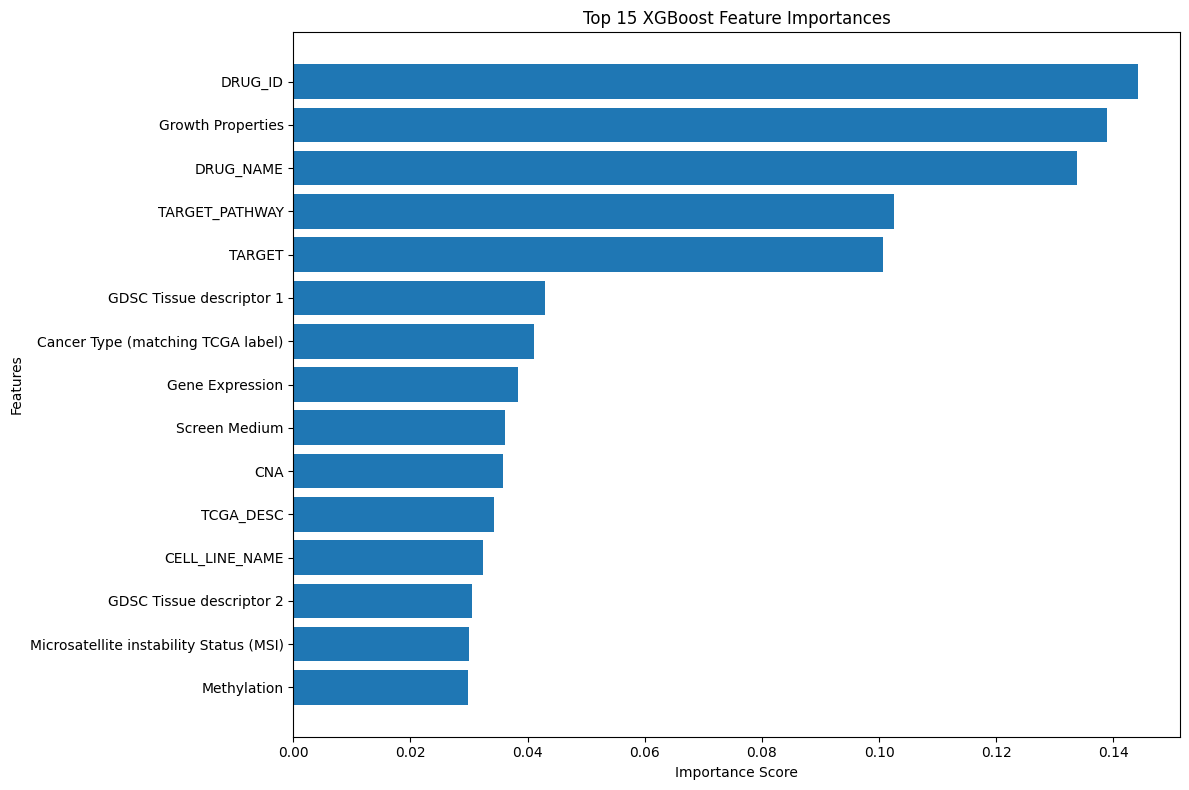

In [13]:
# ============================================================
# STEP 12: XGBoost Feature Importance Analysis
# Purpose:
# Identify the most important biomedical features influencing
# drug sensitivity and resistance prediction.
#
# This improves interpretability of the AI-assisted framework.
# ============================================================

import pandas as pd
from xgboost import XGBClassifier
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 12.1 Extract feature importance values
# ------------------------------------------------------------

try:
    feature_importance_values = xgb_model.feature_importances_
except NameError:

    xgb_model = XGBClassifier(
        n_estimators=200,
        max_depth=10,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
    xgb_model.fit(X_train_scaled, y_train)
    feature_importance_values = xgb_model.feature_importances_
except AttributeError:
    xgb_model.fit(X_train_scaled, y_train)
    feature_importance_values = xgb_model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X_train_encoded.columns,
    "Importance": feature_importance_values
})

# ------------------------------------------------------------
# 12.2 Sort features by importance
# ------------------------------------------------------------

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# ------------------------------------------------------------
# 12.3 Display top important features
# ------------------------------------------------------------

print("Top 15 Important Features:\n")

display(feature_importance.head(15))

# ------------------------------------------------------------
# 12.4 Plot feature importance
# ------------------------------------------------------------

plt.figure(figsize=(12, 8))

plt.barh(
    feature_importance["Feature"].head(15)[::-1],
    feature_importance["Importance"].head(15)[::-1]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Top 15 XGBoost Feature Importances")

plt.tight_layout()
plt.show()

Comparative Model Performance:



,Model,Accuracy,F1_Score,ROC_AUC
0,Random Forest,0.828165,0.828974,0.912603
1,XGBoost,0.852852,0.853379,0.936958
2,SVM,0.623649,0.594994,0.667479
3,ANN,0.780693,0.782913,0.870177


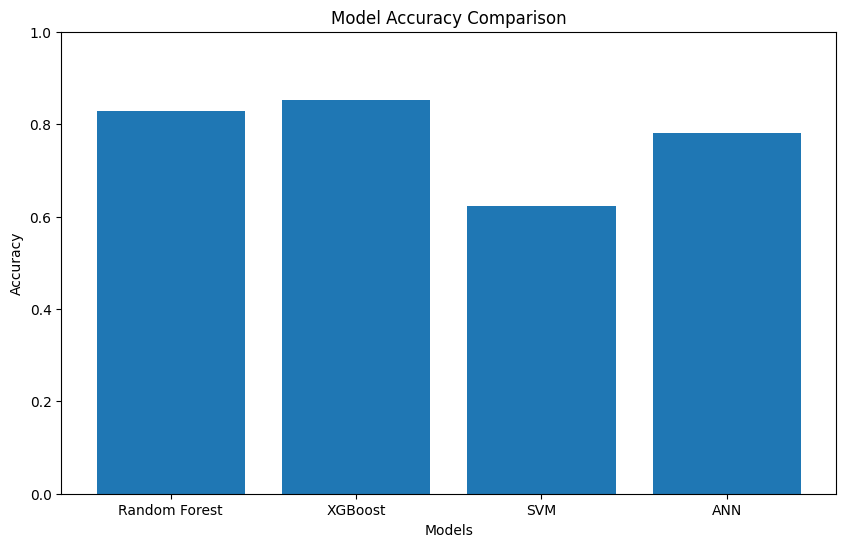

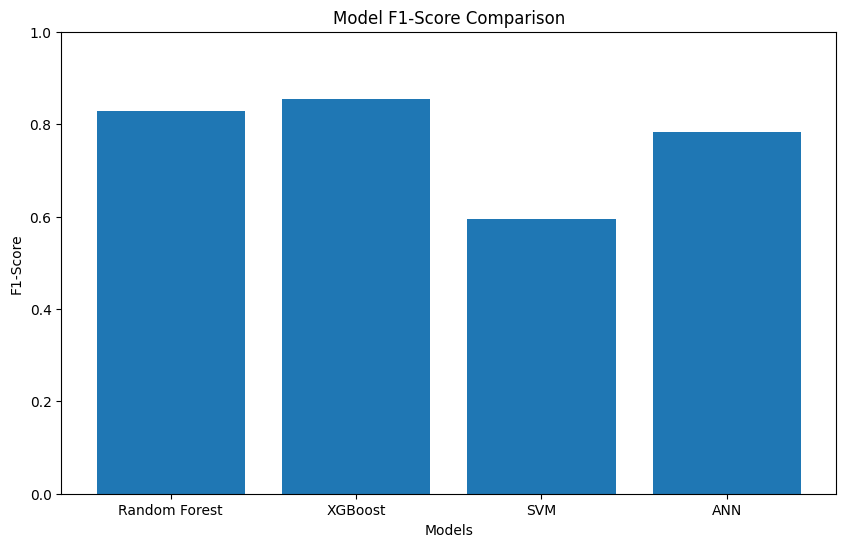

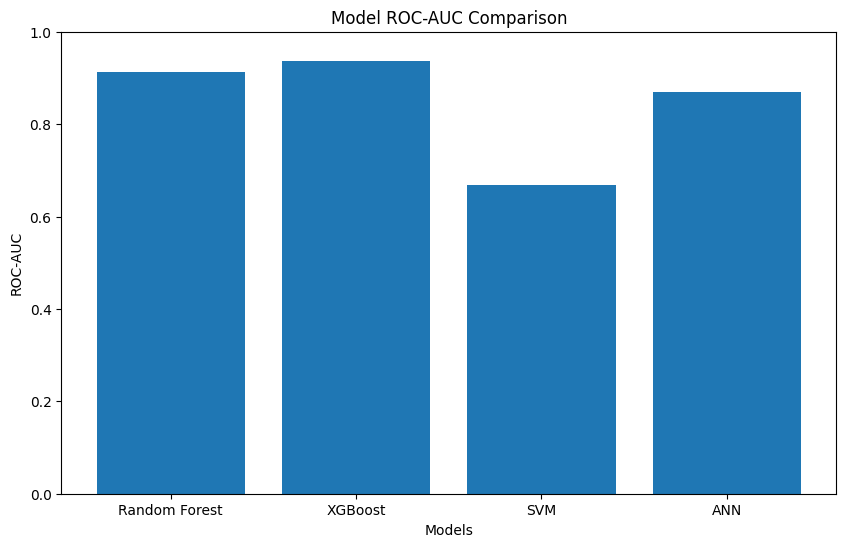

In [14]:
# ============================================================
# STEP 13: Comparative Model Performance Visualization
# Purpose:
# Compare the performance of all ML/DL models using:
# - Accuracy
# - F1-score
# - ROC-AUC
#
# This helps identify the best predictive model for
# AI-assisted Organ-on-a-Chip drug screening systems.
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 13.1 Create performance comparison table
# ------------------------------------------------------------

results_df = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost",
        "SVM",
        "ANN"
    ],

    "Accuracy": [
        rf_accuracy,
        xgb_accuracy,
        svm_accuracy,
        ann_accuracy
    ],

    "F1_Score": [
        rf_f1,
        xgb_f1,
        svm_f1,
        ann_f1
    ],

    "ROC_AUC": [
        rf_auc,
        xgb_auc,
        svm_auc,
        ann_auc
    ]
})

# ------------------------------------------------------------
# 13.2 Display results table
# ------------------------------------------------------------

print("Comparative Model Performance:\n")

display(results_df)

# ------------------------------------------------------------
# 13.3 Plot Accuracy comparison
# ------------------------------------------------------------

plt.figure(figsize=(10,6))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.ylabel("Accuracy")
plt.xlabel("Models")
plt.title("Model Accuracy Comparison")

plt.ylim(0, 1)

plt.show()

# ------------------------------------------------------------
# 13.4 Plot F1-score comparison
# ------------------------------------------------------------

plt.figure(figsize=(10,6))

plt.bar(
    results_df["Model"],
    results_df["F1_Score"]
)

plt.ylabel("F1-Score")
plt.xlabel("Models")
plt.title("Model F1-Score Comparison")

plt.ylim(0, 1)

plt.show()

# ------------------------------------------------------------
# 13.5 Plot ROC-AUC comparison
# ------------------------------------------------------------

plt.figure(figsize=(10,6))

plt.bar(
    results_df["Model"],
    results_df["ROC_AUC"]
)

plt.ylabel("ROC-AUC")
plt.xlabel("Models")
plt.title("Model ROC-AUC Comparison")

plt.ylim(0, 1)

plt.show()

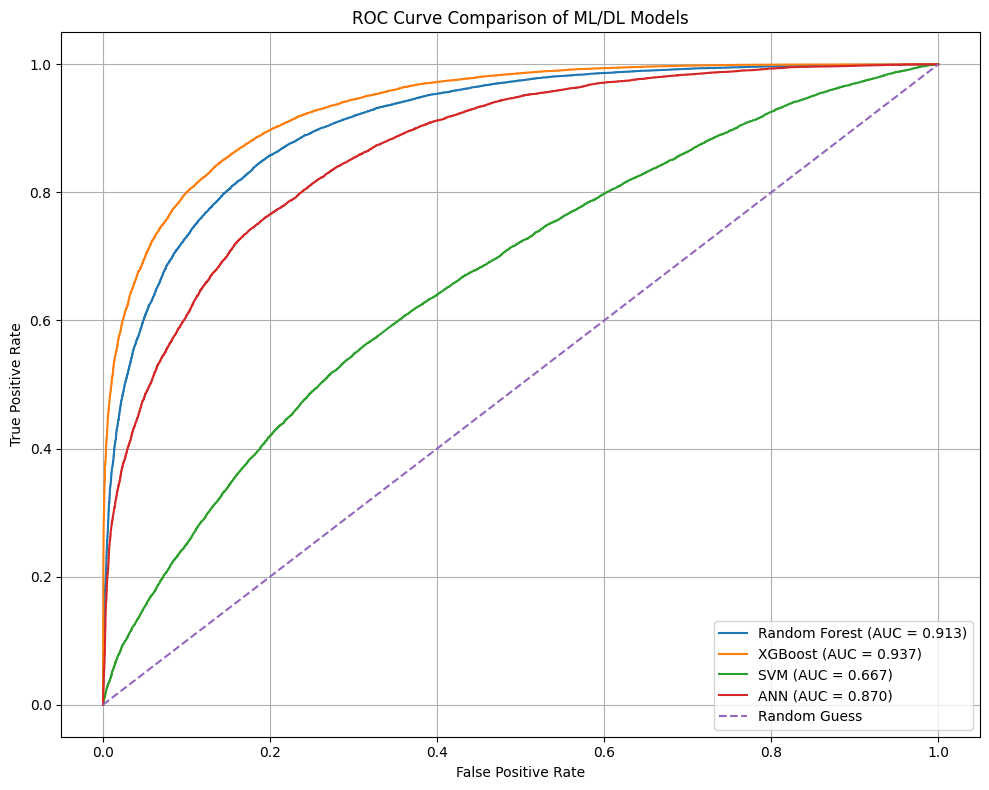

In [15]:
# ============================================================
# FAST ROC CURVE CODE - NO MODEL RETRAINING
# ============================================================

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

roc_data = {
    "Random Forest": y_prob_rf,
    "XGBoost": y_prob_xgb,
    "SVM": y_prob_svm,
    "ANN": y_prob_ann
}

for model_name, y_prob in roc_data.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{model_name} (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison of ML/DL Models")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:
# ============================================================
# STEP 15: Show Drug Sensitivity Prediction Examples
# Purpose:
# Use the best trained model (XGBoost) to show actual prediction
# outputs on test samples.
#
# Output:
# 0 = Resistant
# 1 = Sensitive
# ============================================================

# ------------------------------------------------------------
# 15.1 Predict class and probability using XGBoost
# ------------------------------------------------------------

sample_predictions = X_test.copy()

sample_predictions["Actual_Class"] = y_test.values
sample_predictions["Predicted_Class"] = y_pred_xgb
sample_predictions["Sensitive_Probability"] = y_prob_xgb

# ------------------------------------------------------------
# 15.2 Convert numeric labels into readable labels
# ------------------------------------------------------------

sample_predictions["Actual_Label"] = sample_predictions["Actual_Class"].map({
    1: "Sensitive",
    0: "Resistant"
})

sample_predictions["Predicted_Label"] = sample_predictions["Predicted_Class"].map({
    1: "Sensitive",
    0: "Resistant"
})

# ------------------------------------------------------------
# 15.3 Select important columns for display
# ------------------------------------------------------------

prediction_output = sample_predictions[
    [
        "DRUG_NAME",
        "CELL_LINE_NAME",
        "TCGA_DESC",
        "TARGET",
        "TARGET_PATHWAY",
        "Actual_Label",
        "Predicted_Label",
        "Sensitive_Probability"
    ]
]

# ------------------------------------------------------------
# 15.4 Show first 20 prediction examples
# ------------------------------------------------------------

prediction_output.head(20)

,DRUG_NAME,CELL_LINE_NAME,TCGA_DESC,TARGET,TARGET_PATHWAY,Actual_Label,Predicted_Label,Sensitive_Probability
119092,ML323,HCC-366,UNCLASSIFIED,"USP1, UAF1",Protein stability and degradation,Resistant,Resistant,0.043621
2003,Cisplatin,LAMA-84,LCML,DNA crosslinker,DNA replication,Sensitive,Sensitive,0.925413
197034,P22077,Caov-4,OV,"USP7, USP47",Protein stability and degradation,Sensitive,Resistant,0.188634
182075,AGI-5198,NCI-H929,MM,IDH1 (R132H),Metabolism,Resistant,Resistant,0.231548
106897,LGK974,KP-4,PAAD,PORCN,WNT signaling,Resistant,Resistant,0.135273
128547,IRAK4_4710,SW626,OV,IRAK4,"Other, kinases",Resistant,Resistant,0.024863
171806,LY2109761,MOLP-8,MM,TGFB1,Other,Resistant,Resistant,0.129523
54416,Irinotecan,HOP-92,UNCLASSIFIED,TOP1,DNA replication,Resistant,Resistant,0.464500
118475,ML323,NCI-H1092,SCLC,"USP1, UAF1",Protein stability and degradation,Resistant,Resistant,0.028580
236303,GSK2830371,HL-60,LAML,WIP1,Other,Resistant,Resistant,0.140195


In [17]:
# ============================================================
# STEP 16: Secondary Prediction - LN_IC50 Regression
# Purpose:
# After predicting Sensitive/Resistant classes, we now predict
# the exact continuous drug response score: LN_IC50.
#
# Lower LN_IC50 = higher drug sensitivity
# Higher LN_IC50 = higher drug resistance
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
import numpy as np

# ------------------------------------------------------------
# 16.1 Define regression target
# ------------------------------------------------------------

X_reg = data[feature_columns]
y_reg = data["LN_IC50"]

# ------------------------------------------------------------
# 16.2 Encode categorical features again for regression
# ------------------------------------------------------------

X_reg_encoded = X_reg.copy()

for col in X_reg_encoded.select_dtypes(include=["object"]).columns:
    le = LabelEncoder()
    X_reg_encoded[col] = le.fit_transform(X_reg_encoded[col].astype(str))

# ------------------------------------------------------------
# 16.3 Train-test split for regression
# ------------------------------------------------------------

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg_encoded,
    y_reg,
    test_size=0.20,
    random_state=42
)

# ------------------------------------------------------------
# 16.4 Scale regression features
# ------------------------------------------------------------

reg_scaler = StandardScaler()

X_reg_train_scaled = reg_scaler.fit_transform(X_reg_train)
X_reg_test_scaled = reg_scaler.transform(X_reg_test)

print("Regression training shape:", X_reg_train_scaled.shape)
print("Regression testing shape:", X_reg_test_scaled.shape)

C:\Users\Ushas\AppData\Local\Temp\ipykernel_5216\3118989571.py:30: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in X_reg_encoded.select_dtypes(include=["object"]).columns:


Regression training shape: (193628, 16)
Regression testing shape: (48407, 16)


In [18]:
# ============================================================
# STEP 17: Random Forest Regressor
# Purpose:
# Predict continuous LN_IC50 drug response scores.
#
# Evaluation Metrics:
# - MAE
# - RMSE
# - R² Score
# ============================================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

# ------------------------------------------------------------
# 17.1 Initialize Random Forest Regressor
# ------------------------------------------------------------

rf_regressor = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

# ------------------------------------------------------------
# 17.2 Train model
# ------------------------------------------------------------

print("Training Random Forest Regressor...")

rf_regressor.fit(
    X_reg_train_scaled,
    y_reg_train
)

print("Training completed.")

# ------------------------------------------------------------
# 17.3 Predict on test data
# ------------------------------------------------------------

y_pred_rf_reg = rf_regressor.predict(
    X_reg_test_scaled
)

# ------------------------------------------------------------
# 17.4 Evaluate regression performance
# ------------------------------------------------------------

rf_mae = mean_absolute_error(
    y_reg_test,
    y_pred_rf_reg
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_reg_test,
        y_pred_rf_reg
    )
)

rf_r2 = r2_score(
    y_reg_test,
    y_pred_rf_reg
)

# ------------------------------------------------------------
# 17.5 Print results
# ------------------------------------------------------------

print("\n========== Random Forest Regression Results ==========")

print(f"MAE   : {rf_mae:.4f}")
print(f"RMSE  : {rf_rmse:.4f}")
print(f"R²    : {rf_r2:.4f}")

Training Random Forest Regressor...
Training completed.

========== Random Forest Regression Results ==========
MAE   : 0.9590
RMSE  : 1.2813
R²    : 0.7848


In [19]:
# ============================================================
# STEP 18: XGBoost Regressor
# Purpose:
# Predict continuous LN_IC50 drug-response scores using
# gradient boosting regression.
#
# Expected:
# Better regression performance than Random Forest.
# ============================================================

from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

# ------------------------------------------------------------
# 18.1 Initialize XGBoost Regressor
# ------------------------------------------------------------

xgb_regressor = XGBRegressor(
    n_estimators=200,
    max_depth=10,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1
)

# ------------------------------------------------------------
# 18.2 Train model
# ------------------------------------------------------------

print("Training XGBoost Regressor...")

xgb_regressor.fit(
    X_reg_train_scaled,
    y_reg_train
)

print("Training completed.")

# ------------------------------------------------------------
# 18.3 Predict on test data
# ------------------------------------------------------------

y_pred_xgb_reg = xgb_regressor.predict(
    X_reg_test_scaled
)

# ------------------------------------------------------------
# 18.4 Evaluate regression performance
# ------------------------------------------------------------

xgb_mae = mean_absolute_error(
    y_reg_test,
    y_pred_xgb_reg
)

xgb_rmse = np.sqrt(
    mean_squared_error(
        y_reg_test,
        y_pred_xgb_reg
    )
)

xgb_r2 = r2_score(
    y_reg_test,
    y_pred_xgb_reg
)

# ------------------------------------------------------------
# 18.5 Print results
# ------------------------------------------------------------

print("\n========== XGBoost Regression Results ==========")

print(f"MAE   : {xgb_mae:.4f}")
print(f"RMSE  : {xgb_rmse:.4f}")
print(f"R²    : {xgb_r2:.4f}")

Training XGBoost Regressor...
Training completed.

========== XGBoost Regression Results ==========
MAE   : 0.8099
RMSE  : 1.0842
R²    : 0.8459


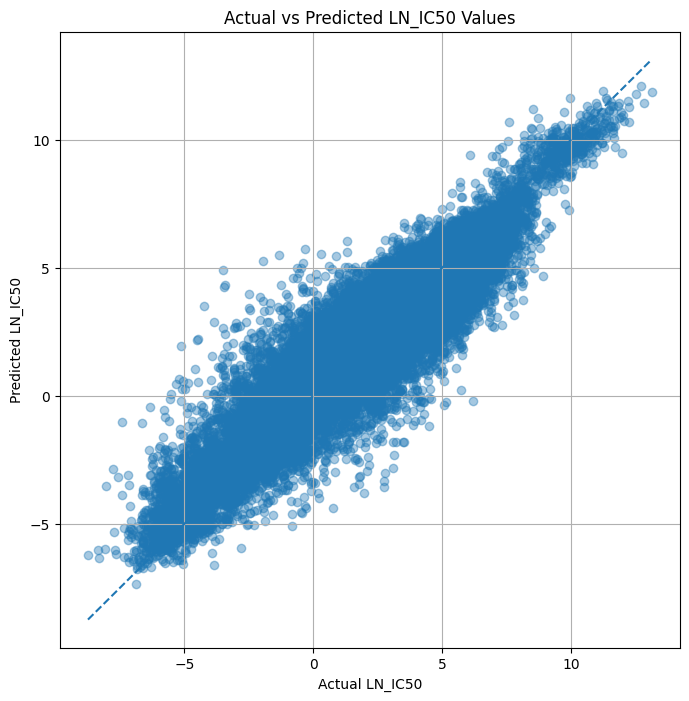

In [20]:
# ============================================================
# STEP 19: Regression Prediction Visualization
# Purpose:
# Visualize actual vs predicted LN_IC50 values using the
# best regression model (XGBoost Regressor).
#
# This helps evaluate how closely the predicted drug-response
# scores match the actual biomedical response values.
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 19.1 Create scatter plot
# ------------------------------------------------------------

plt.figure(figsize=(8, 8))

plt.scatter(
    y_reg_test,
    y_pred_xgb_reg,
    alpha=0.4
)

# ------------------------------------------------------------
# 19.2 Add ideal prediction line
# Purpose:
# Perfect predictions should lie close to this diagonal line.
# ------------------------------------------------------------

min_val = min(y_reg_test.min(), y_pred_xgb_reg.min())
max_val = max(y_reg_test.max(), y_pred_xgb_reg.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle='--'
)

# ------------------------------------------------------------
# 19.3 Figure formatting
# ------------------------------------------------------------

plt.xlabel("Actual LN_IC50")
plt.ylabel("Predicted LN_IC50")

plt.title("Actual vs Predicted LN_IC50 Values")

plt.grid(True)

plt.show()

In [25]:
# ============================================================
# STEP 20B: Create readable Future OoC Integration Output
# Purpose:
# Display final simulated OoC prediction results with original
# readable drug names, cell line names, cancer type, targets,
# predicted class, predicted LN_IC50, and AI recommendation.
# ============================================================

# Use original readable test data
ooc_readable_output = X_test.copy()

# Add actual and predicted outputs
ooc_readable_output["Actual_LN_IC50"] = y_reg_test.values
ooc_readable_output["Actual_LN_IC50"] = data.loc[X_test.index, "LN_IC50"].values

ooc_predicted_ln_ic50 = xgb_regressor.predict(
    reg_scaler.transform(X_test_encoded)
)

ooc_readable_output["Predicted_LN_IC50"] = ooc_predicted_ln_ic50
ooc_class_prediction = y_pred_xgb
ooc_readable_output["Sensitive_Probability"] = y_prob_xgb
ooc_readable_output["Predicted_Response"] = ooc_class_prediction

# Convert numeric response to readable label
ooc_readable_output["Predicted_Response"] = ooc_readable_output["Predicted_Response"].map({
    1: "Sensitive",
    0: "Resistant"
})

# Add recommendation
def drug_recommendation(row):
    if row["Predicted_Response"] == "Sensitive":
        if row["Sensitive_Probability"] >= 0.75:
            return "Strongly recommend for OoC testing"
        elif row["Sensitive_Probability"] >= 0.50:
            return "Recommend for OoC testing"
        else:
            return "Review before OoC testing"
    return "Do not recommend for OoC testing"

ooc_readable_output["AI_OoC_Recommendation"] = ooc_readable_output.apply(
    drug_recommendation,
    axis=1
)

# Select paper-ready columns
final_ooc_output = ooc_readable_output[
    [
        "DRUG_NAME",
        "CELL_LINE_NAME",
        "TCGA_DESC",
        "TARGET",
        "TARGET_PATHWAY",
        "Actual_LN_IC50",
        "Predicted_LN_IC50",
        "Predicted_Response",
        "Sensitive_Probability",
        "AI_OoC_Recommendation"
    ]
]

final_ooc_output.head(20)

,DRUG_NAME,CELL_LINE_NAME,TCGA_DESC,TARGET,TARGET_PATHWAY,Actual_LN_IC50,Predicted_LN_IC50,Predicted_Response,Sensitive_Probability,AI_OoC_Recommendation
119092,ML323,HCC-366,UNCLASSIFIED,"USP1, UAF1",Protein stability and degradation,6.350836,5.267447,Resistant,0.043621,Do not recommend for OoC testing
2003,Cisplatin,LAMA-84,LCML,DNA crosslinker,DNA replication,1.329829,1.149349,Sensitive,0.925413,Strongly recommend for OoC testing
197034,P22077,Caov-4,OV,"USP7, USP47",Protein stability and degradation,2.300808,4.624172,Resistant,0.188634,Do not recommend for OoC testing
182075,AGI-5198,NCI-H929,MM,IDH1 (R132H),Metabolism,3.998790,3.451396,Resistant,0.231548,Do not recommend for OoC testing
106897,LGK974,KP-4,PAAD,PORCN,WNT signaling,3.871467,4.015344,Resistant,0.135273,Do not recommend for OoC testing
128547,IRAK4_4710,SW626,OV,IRAK4,"Other, kinases",5.711652,5.704351,Resistant,0.024863,Do not recommend for OoC testing
171806,LY2109761,MOLP-8,MM,TGFB1,Other,4.809710,3.793478,Resistant,0.129523,Do not recommend for OoC testing
54416,Irinotecan,HOP-92,UNCLASSIFIED,TOP1,DNA replication,3.314986,3.258978,Resistant,0.464500,Do not recommend for OoC testing
118475,ML323,NCI-H1092,SCLC,"USP1, UAF1",Protein stability and degradation,4.662331,4.679954,Resistant,0.028580,Do not recommend for OoC testing
236303,GSK2830371,HL-60,LAML,WIP1,Other,3.331508,3.831873,Resistant,0.140195,Do not recommend for OoC testing


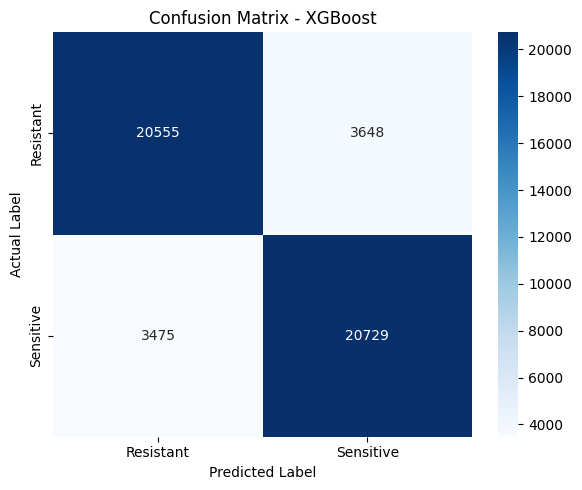

In [26]:
# ============================================================
# STEP 21: XGBoost Confusion Matrix Heatmap
# Purpose:
# Visualize classification performance of the best model
# (XGBoost) using a confusion matrix heatmap.
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# ------------------------------------------------------------
# 21.1 Compute confusion matrix
# ------------------------------------------------------------

cm_xgb = confusion_matrix(y_test, y_pred_xgb)

# ------------------------------------------------------------
# 21.2 Plot heatmap
# ------------------------------------------------------------

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_xgb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Resistant", "Sensitive"],
    yticklabels=["Resistant", "Sensitive"]
)

# ------------------------------------------------------------
# 21.3 Figure formatting
# ------------------------------------------------------------

plt.title("Confusion Matrix - XGBoost")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()

plt.show()

In [27]:
# ============================================================
# REVIEWER-REQUESTED FIGURES FOR CHAPTER 9
# AI-Assisted Organ-on-a-Chip Drug Response Prediction
# Run this cell after training RF, XGBoost, SVM, ANN,
# and XGBoost Regressor.
# ============================================================

import os
import sys
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# 0. Create output folder for publication figures
# ------------------------------------------------------------

FIG_DIR = "chapter9_reviewer_figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(filename):
    path = os.path.join(FIG_DIR, filename)
    plt.tight_layout()
    plt.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved: {path}")


# ------------------------------------------------------------
# 1. Basic checks
# ------------------------------------------------------------

required_vars = [
    "data",
    "X_train_encoded",
    "X_test_encoded",
    "X_train_scaled",
    "X_test_scaled",
    "y_test",
    "y_pred_rf",
    "y_pred_xgb",
    "y_pred_svm",
    "y_pred_ann",
    "y_prob_rf",
    "y_prob_xgb",
    "y_prob_svm",
    "y_prob_ann",
    "xgb_model",
    "y_reg_test",
    "y_pred_xgb_reg",
    "xgb_regressor"
]

missing_vars = [v for v in required_vars if v not in globals()]

if missing_vars:
    raise NameError(
        "Run previous model training cells first. Missing variables: "
        + ", ".join(missing_vars)
    )

# Convert probabilities to 1D arrays
y_prob_rf = np.asarray(y_prob_rf).ravel()
y_prob_xgb = np.asarray(y_prob_xgb).ravel()
y_prob_svm = np.asarray(y_prob_svm).ravel()
y_prob_ann = np.asarray(y_prob_ann).ravel()

# Create DataFrame versions for explainability
feature_names = list(X_train_encoded.columns)

X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=feature_names
)

X_test_scaled_df = pd.DataFrame(
    X_test_scaled,
    columns=feature_names,
    index=X_test_encoded.index
)

print("All required variables are available.")

All required variables are available.


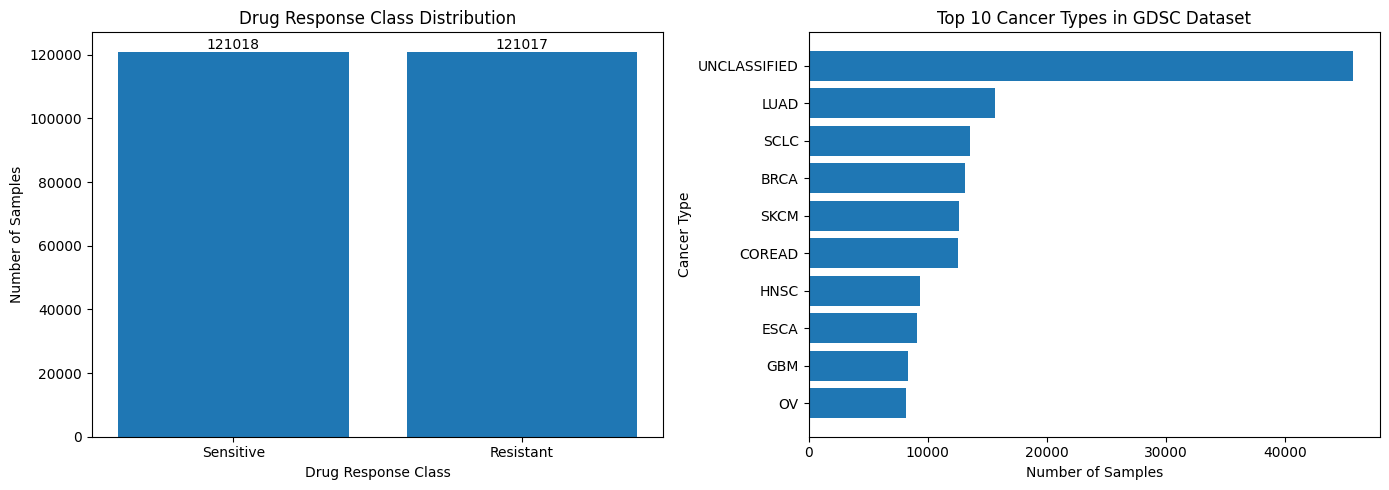

Saved: chapter9_reviewer_figures\Figure_1_Dataset_and_Target_Distribution.png


In [28]:
# ============================================================
# FIGURE 1: Dataset and Target Distribution
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Class distribution
class_counts = data["Drug_Response_Class"].map({
    0: "Resistant",
    1: "Sensitive"
}).value_counts()

axes[0].bar(class_counts.index, class_counts.values)
axes[0].set_title("Drug Response Class Distribution")
axes[0].set_xlabel("Drug Response Class")
axes[0].set_ylabel("Number of Samples")

for i, v in enumerate(class_counts.values):
    axes[0].text(i, v, str(v), ha="center", va="bottom", fontsize=10)

# Top cancer types
if "TCGA_DESC" in data.columns:
    cancer_col = "TCGA_DESC"
elif "Cancer Type (matching TCGA label)" in data.columns:
    cancer_col = "Cancer Type (matching TCGA label)"
else:
    cancer_col = None

if cancer_col:
    top_cancers = data[cancer_col].value_counts().head(10)
    axes[1].barh(top_cancers.index, top_cancers.values)
    axes[1].set_title("Top 10 Cancer Types in GDSC Dataset")
    axes[1].set_xlabel("Number of Samples")
    axes[1].set_ylabel("Cancer Type")
    axes[1].invert_yaxis()
else:
    axes[1].text(0.5, 0.5, "Cancer type column not found", ha="center")
    axes[1].axis("off")

save_fig("Figure_1_Dataset_and_Target_Distribution.png")

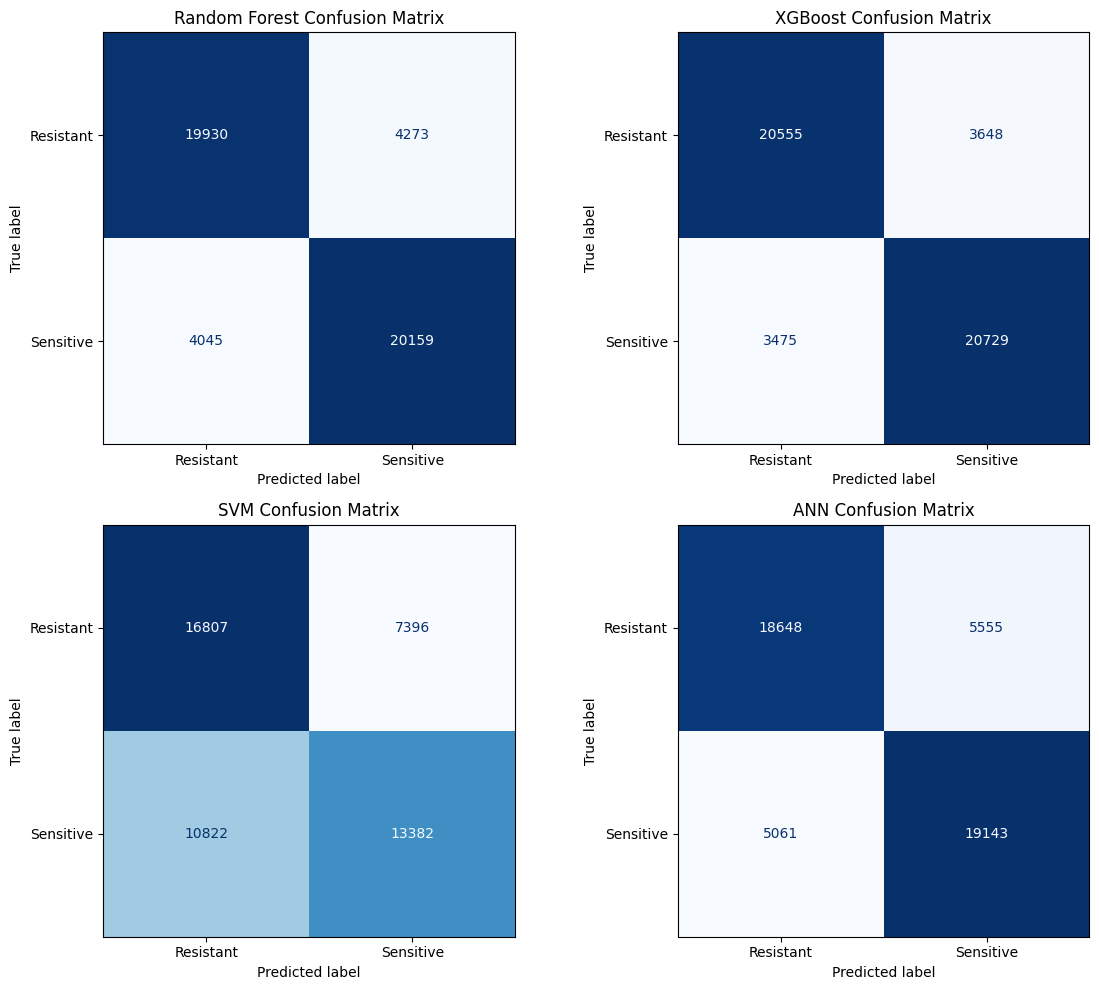

Saved: chapter9_reviewer_figures\Figure_2_Confusion_Matrices_All_Models.png


In [29]:
# ============================================================
# FIGURE 2: Confusion Matrices for All Classification Models
# ============================================================

model_predictions = {
    "Random Forest": y_pred_rf,
    "XGBoost": y_pred_xgb,
    "SVM": y_pred_svm,
    "ANN": y_pred_ann
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for ax, (model_name, y_pred) in zip(axes, model_predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Resistant", "Sensitive"]
    )
    
    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )
    
    ax.set_title(f"{model_name} Confusion Matrix")

save_fig("Figure_2_Confusion_Matrices_All_Models.png")

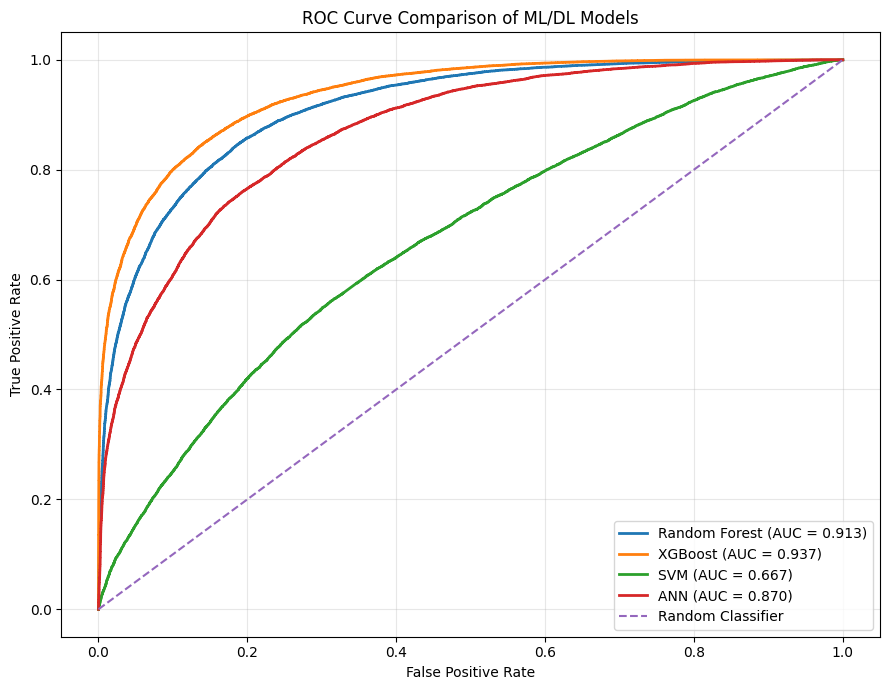

Saved: chapter9_reviewer_figures\Figure_3_ROC_Curve_Comparison.png


In [30]:
# ============================================================
# FIGURE 3: ROC Curve Comparison of All Models
# ============================================================

roc_data = {
    "Random Forest": y_prob_rf,
    "XGBoost": y_prob_xgb,
    "SVM": y_prob_svm,
    "ANN": y_prob_ann
}

plt.figure(figsize=(9, 7))

for model_name, y_prob in roc_data.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    
    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{model_name} (AUC = {roc_auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison of ML/DL Models")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)

save_fig("Figure_3_ROC_Curve_Comparison.png")

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Random Forest,0.828165,0.825106,0.832879,0.828974,0.912603
1,XGBoost,0.852852,0.850351,0.856429,0.853379,0.936958
2,SVM,0.623649,0.644047,0.552884,0.594994,0.667479
3,ANN,0.780693,0.775083,0.790902,0.782913,0.870177


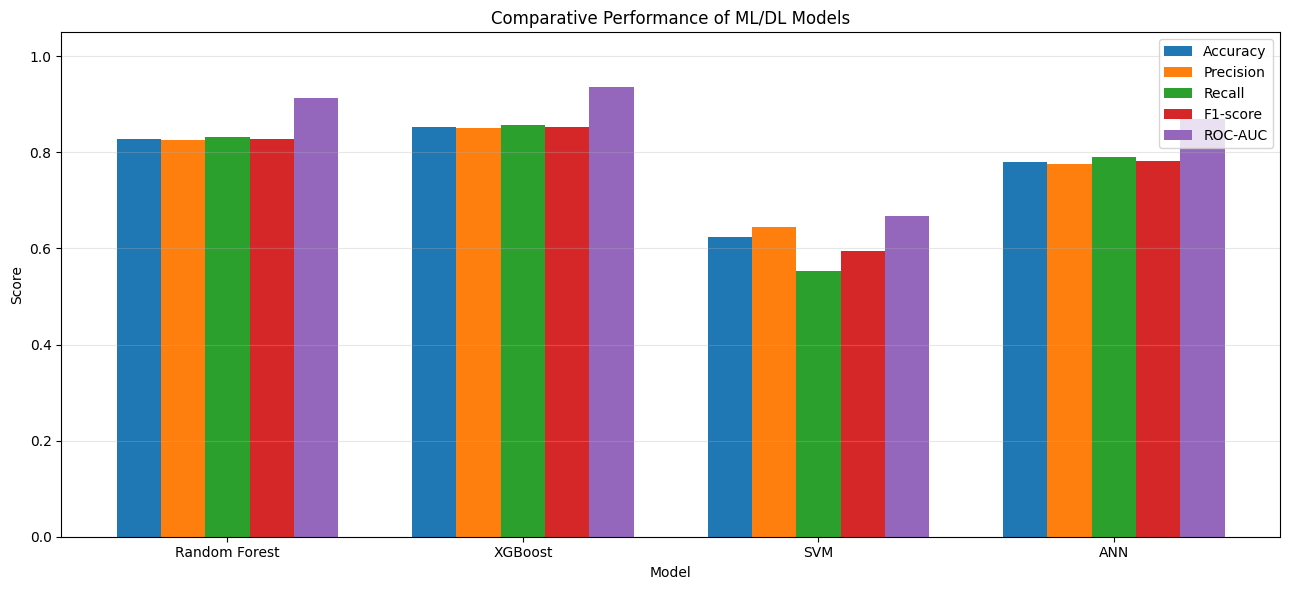

Saved: chapter9_reviewer_figures\Figure_4_Model_Performance_Comparison.png


In [31]:
# ============================================================
# FIGURE 4: Model Performance Comparison
# ============================================================

performance_rows = []

model_outputs = {
    "Random Forest": (y_pred_rf, y_prob_rf),
    "XGBoost": (y_pred_xgb, y_prob_xgb),
    "SVM": (y_pred_svm, y_prob_svm),
    "ANN": (y_pred_ann, y_prob_ann)
}

for model_name, (y_pred, y_prob) in model_outputs.items():
    performance_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

performance_df = pd.DataFrame(performance_rows)

display(performance_df)

metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]

x = np.arange(len(performance_df["Model"]))
width = 0.15

plt.figure(figsize=(13, 6))

for i, metric in enumerate(metrics_to_plot):
    plt.bar(
        x + i * width,
        performance_df[metric],
        width,
        label=metric
    )

plt.xticks(
    x + width * 2,
    performance_df["Model"]
)

plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.xlabel("Model")
plt.title("Comparative Performance of ML/DL Models")
plt.legend()
plt.grid(axis="y", alpha=0.3)

save_fig("Figure_4_Model_Performance_Comparison.png")

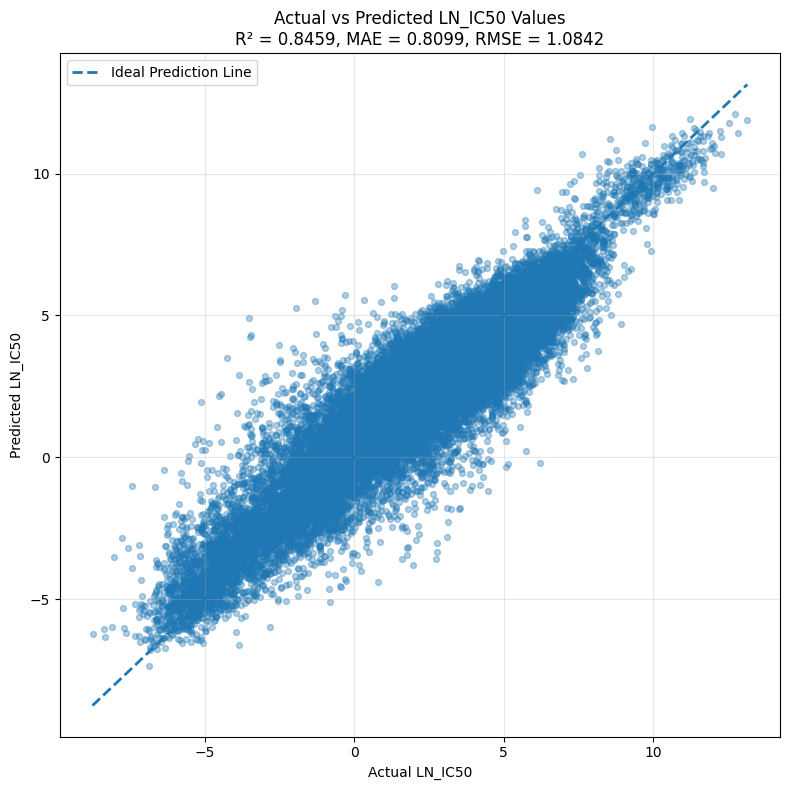

Saved: chapter9_reviewer_figures\Figure_5_Actual_vs_Predicted_LN_IC50.png


In [32]:
# ============================================================
# FIGURE 5: Actual vs Predicted LN_IC50 Values
# ============================================================

plt.figure(figsize=(8, 8))

plt.scatter(
    y_reg_test,
    y_pred_xgb_reg,
    alpha=0.35,
    s=18
)

min_val = min(y_reg_test.min(), y_pred_xgb_reg.min())
max_val = max(y_reg_test.max(), y_pred_xgb_reg.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--",
    linewidth=2,
    label="Ideal Prediction Line"
)

r2 = r2_score(y_reg_test, y_pred_xgb_reg)
mae = mean_absolute_error(y_reg_test, y_pred_xgb_reg)
rmse = np.sqrt(mean_squared_error(y_reg_test, y_pred_xgb_reg))

plt.xlabel("Actual LN_IC50")
plt.ylabel("Predicted LN_IC50")
plt.title(
    f"Actual vs Predicted LN_IC50 Values\n"
    f"R² = {r2:.4f}, MAE = {mae:.4f}, RMSE = {rmse:.4f}"
)
plt.legend()
plt.grid(True, alpha=0.3)

save_fig("Figure_5_Actual_vs_Predicted_LN_IC50.png")

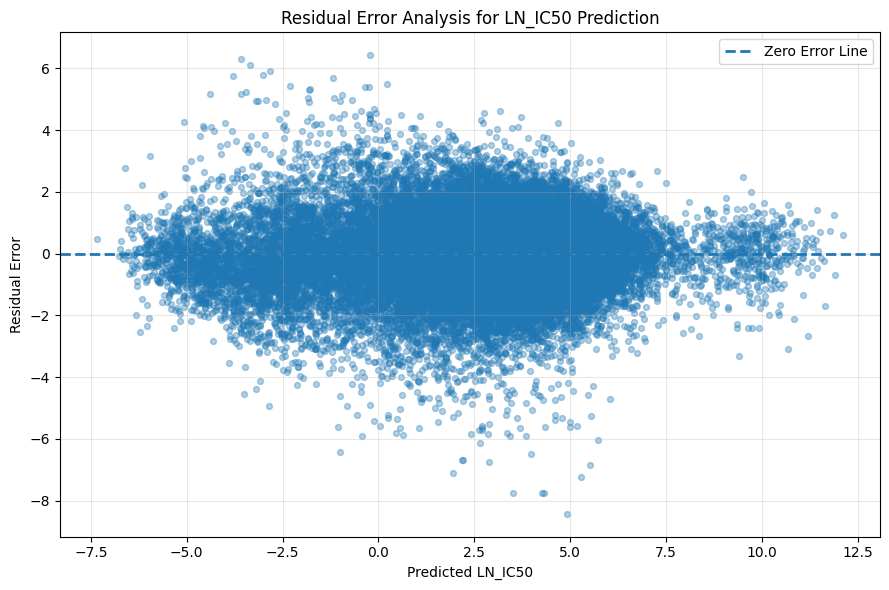

Saved: chapter9_reviewer_figures\Figure_6_LN_IC50_Residual_Plot.png


In [33]:
# ============================================================
# FIGURE 6: Residual Plot for LN_IC50 Prediction
# ============================================================

residuals = y_reg_test - y_pred_xgb_reg

plt.figure(figsize=(9, 6))

plt.scatter(
    y_pred_xgb_reg,
    residuals,
    alpha=0.35,
    s=18
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=2,
    label="Zero Error Line"
)

plt.xlabel("Predicted LN_IC50")
plt.ylabel("Residual Error")
plt.title("Residual Error Analysis for LN_IC50 Prediction")
plt.legend()
plt.grid(True, alpha=0.3)

save_fig("Figure_6_LN_IC50_Residual_Plot.png")

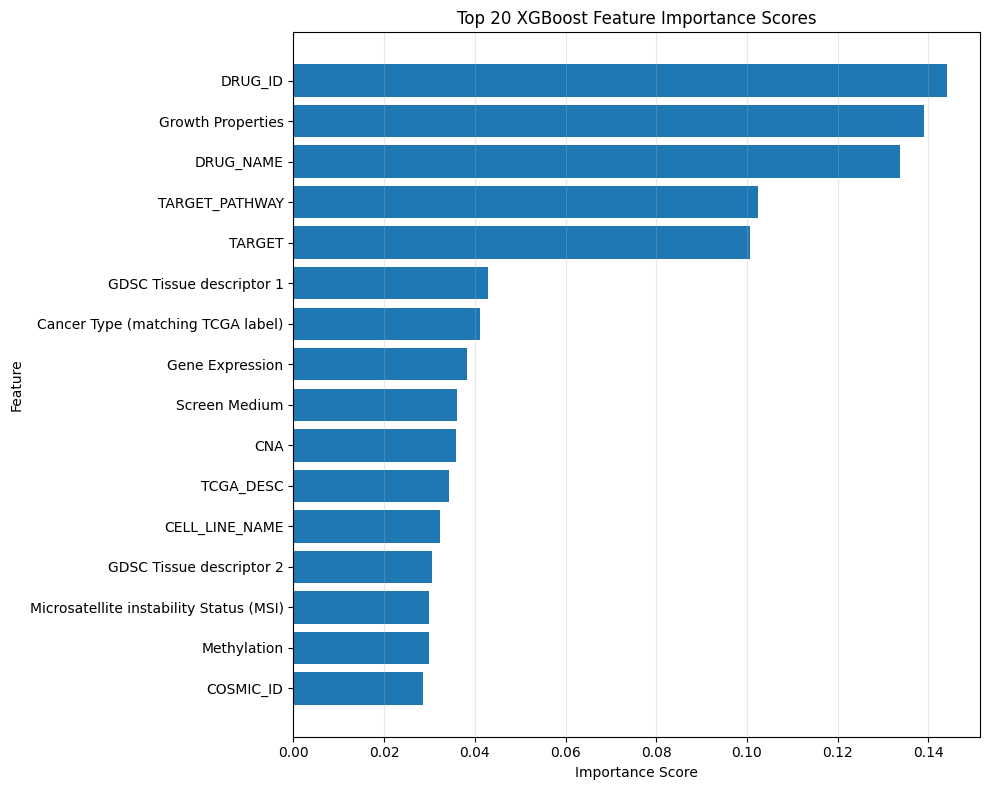

Saved: chapter9_reviewer_figures\Figure_7_XGBoost_Feature_Importance.png


In [34]:
# ============================================================
# FIGURE 7: XGBoost Feature Importance
# ============================================================

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

top_features = feature_importance.head(20)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Top 20 XGBoost Feature Importance Scores")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)

save_fig("Figure_7_XGBoost_Feature_Importance.png")

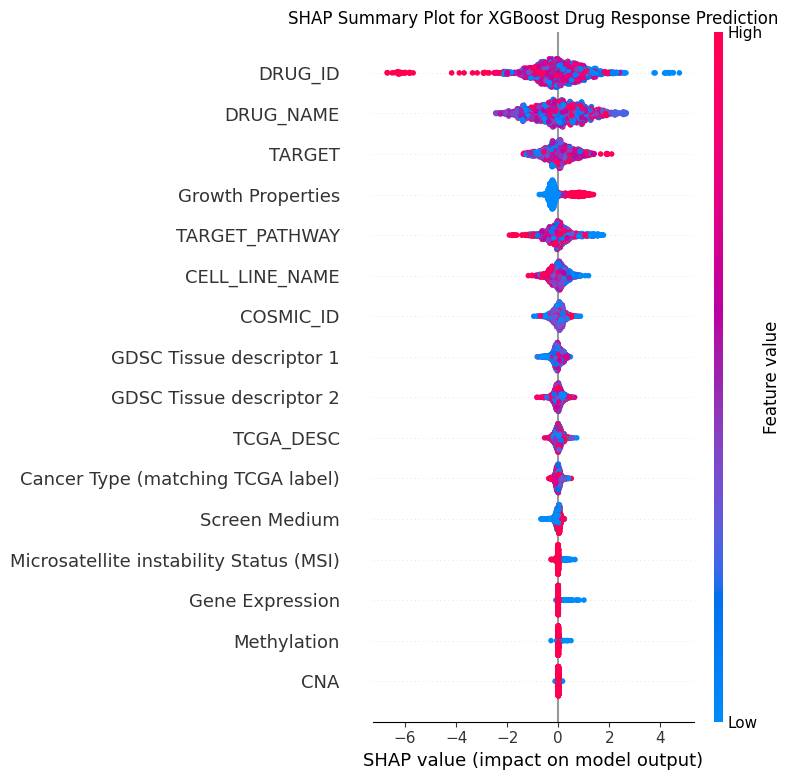

Saved: chapter9_reviewer_figures\Figure_8_SHAP_Summary_XGBoost.png


In [35]:
# ============================================================
# FIGURE 8: SHAP Summary Plot for XGBoost
# ============================================================

try:
    import shap
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "shap", "-q"])
    import shap

# Use sample to avoid very slow execution
sample_size = min(2000, X_test_scaled_df.shape[0])

X_shap = X_test_scaled_df.sample(
    n=sample_size,
    random_state=42
)

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_shap)

# Handle binary classifier output format
if isinstance(shap_values, list):
    shap_values_to_plot = shap_values[1]
else:
    shap_values_to_plot = shap_values

plt.figure()

shap.summary_plot(
    shap_values_to_plot,
    X_shap,
    max_display=20,
    show=False
)

plt.title("SHAP Summary Plot for XGBoost Drug Response Prediction")

save_fig("Figure_8_SHAP_Summary_XGBoost.png")

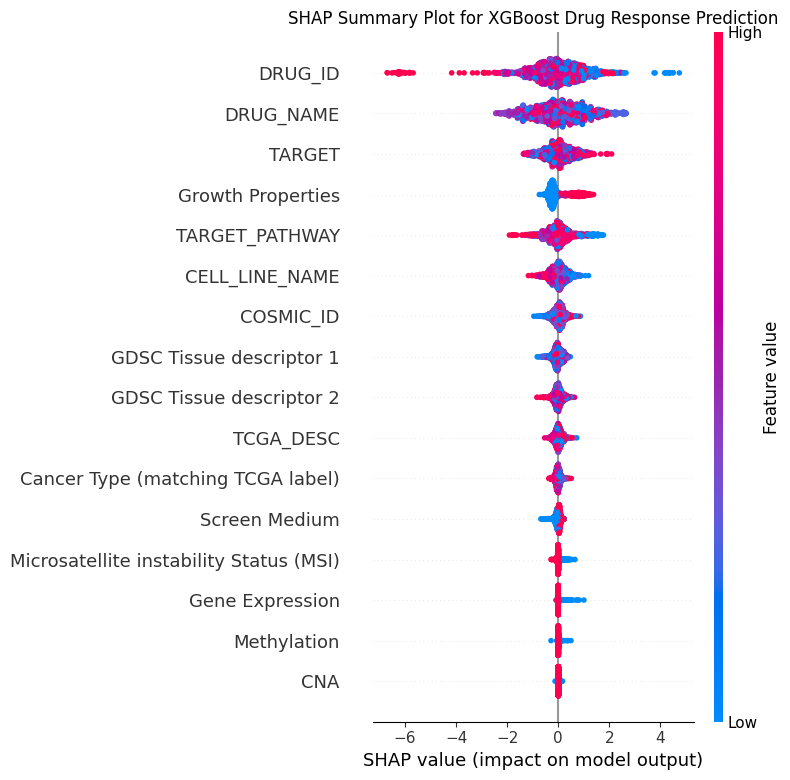

Saved: chapter9_reviewer_figures\Figure_8_SHAP_Summary_XGBoost.png


In [36]:
# ============================================================
# FIGURE 8: SHAP Summary Plot for XGBoost
# ============================================================

try:
    import shap
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "shap", "-q"])
    import shap

# Use sample to avoid very slow execution
sample_size = min(2000, X_test_scaled_df.shape[0])

X_shap = X_test_scaled_df.sample(
    n=sample_size,
    random_state=42
)

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_shap)

# Handle binary classifier output format
if isinstance(shap_values, list):
    shap_values_to_plot = shap_values[1]
else:
    shap_values_to_plot = shap_values

plt.figure()

shap.summary_plot(
    shap_values_to_plot,
    X_shap,
    max_display=20,
    show=False
)

plt.title("SHAP Summary Plot for XGBoost Drug Response Prediction")

save_fig("Figure_8_SHAP_Summary_XGBoost.png")

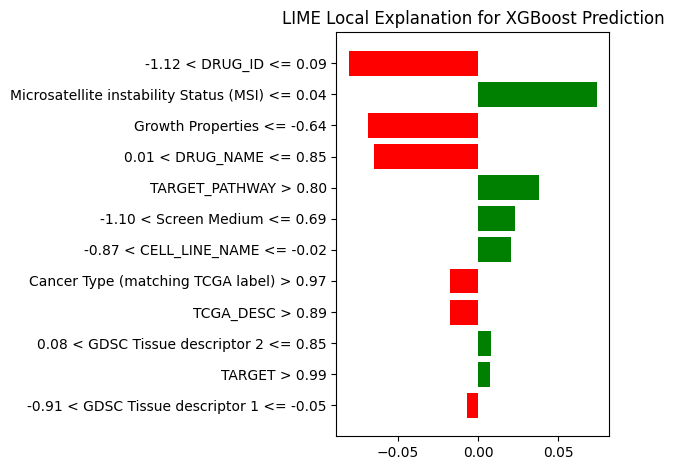

Saved: chapter9_reviewer_figures\Figure_10_LIME_Local_Explanation.png


In [37]:
# ============================================================
# FIGURE 10: LIME Local Explanation for One Test Sample
# ============================================================

try:
    from lime.lime_tabular import LimeTabularExplainer
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "lime", "-q"])
    from lime.lime_tabular import LimeTabularExplainer

lime_explainer = LimeTabularExplainer(
    training_data=X_train_scaled_df.values,
    feature_names=feature_names,
    class_names=["Resistant", "Sensitive"],
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

# Select one representative correctly classified XGBoost sample
correct_indices = np.where(np.asarray(y_test) == np.asarray(y_pred_xgb))[0]

if len(correct_indices) > 0:
    sample_index = correct_indices[0]
else:
    sample_index = 0

lime_exp = lime_explainer.explain_instance(
    data_row=X_test_scaled_df.iloc[sample_index].values,
    predict_fn=xgb_model.predict_proba,
    num_features=12
)

fig = lime_exp.as_pyplot_figure()
plt.title("LIME Local Explanation for XGBoost Prediction")

save_fig("Figure_10_LIME_Local_Explanation.png")

Best Model: XGBoost
Accuracy : 0.8529
Precision: 0.8504
Recall   : 0.8564
F1-score : 0.8534
ROC-AUC  : 0.9370


<Figure size 700x600 with 0 Axes>

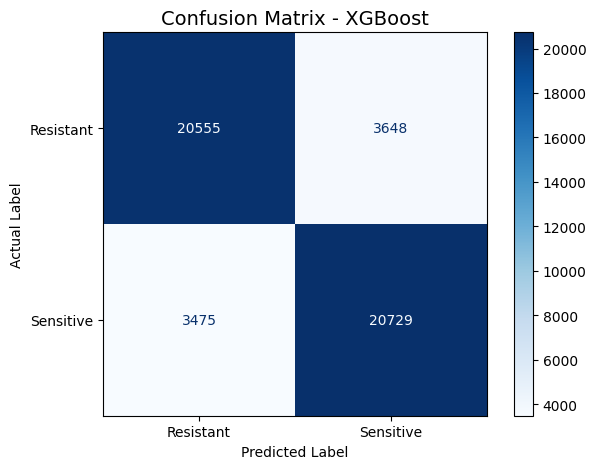

Saved figure at: chapter9_reviewer_figures\Best_Model_Confusion_Matrix_XGBoost.png


In [39]:
# ============================================================
# CONFUSION MATRIX FOR BEST MODEL
# Best model selected using ROC-AUC score
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# 1. Create folder to save figure
# ------------------------------------------------------------

FIG_DIR = "chapter9_reviewer_figures"
os.makedirs(FIG_DIR, exist_ok=True)

# ------------------------------------------------------------
# 2. Store model predictions and probabilities
# ------------------------------------------------------------

models = {
    "Random Forest": {
        "y_pred": y_pred_rf,
        "y_prob": y_prob_rf
    },
    "XGBoost": {
        "y_pred": y_pred_xgb,
        "y_prob": y_prob_xgb
    },
    "SVM": {
        "y_pred": y_pred_svm,
        "y_prob": y_prob_svm
    },
    "ANN": {
        "y_pred": y_pred_ann,
        "y_prob": y_prob_ann
    }
}

# ------------------------------------------------------------
# 3. Find best model using ROC-AUC
# ------------------------------------------------------------

best_model_name = None
best_auc = -1

for model_name, output in models.items():
    auc_score = roc_auc_score(y_test, output["y_prob"])
    
    if auc_score > best_auc:
        best_auc = auc_score
        best_model_name = model_name

best_y_pred = models[best_model_name]["y_pred"]
best_y_prob = models[best_model_name]["y_prob"]

# ------------------------------------------------------------
# 4. Calculate performance metrics
# ------------------------------------------------------------

accuracy = accuracy_score(y_test, best_y_pred)
precision = precision_score(y_test, best_y_pred)
recall = recall_score(y_test, best_y_pred)
f1 = f1_score(y_test, best_y_pred)
roc_auc = roc_auc_score(y_test, best_y_prob)

print("Best Model:", best_model_name)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

# ------------------------------------------------------------
# 5. Generate confusion matrix
# 0 = Resistant, 1 = Sensitive
# ------------------------------------------------------------

cm = confusion_matrix(y_test, best_y_pred, labels=[0, 1])

plt.figure(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Resistant", "Sensitive"]
)

disp.plot(
    cmap="Blues",
    values_format="d",
    colorbar=True
)

plt.title(f"Confusion Matrix - {best_model_name}", fontsize=14)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()

# ------------------------------------------------------------
# 6. Save figure
# ------------------------------------------------------------

save_path = os.path.join(
    FIG_DIR,
    f"Best_Model_Confusion_Matrix_{best_model_name.replace(' ', '_')}.png"
)

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved figure at: {save_path}")